Main simulation figure

In [1]:
# ============================================================
# Main IsoVita simulation study
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import isovita as iso
import isovita_simulation as isim


# ============================================================
# 1. Reference simulation configuration
# ============================================================

# Production IsoVita has exactly two inferential branches.
BRANCHES = (
    "discrete",
    "continuous",
)

# Main simulation alternatives correspond exactly to the
# two production hypotheses.
TRUTH_TYPES = (
    "discrete",
    "continuous",
)

SIGNAL_STRENGTHS = np.array(
    [0.05, 0.10, 0.20, 0.40, 0.80],
    dtype=float,
)

N_SAMPLES = 180
K = 4

# Two genes for every:
# trajectory truth × signal-strength combination.
GENES_PER_CELL = 2

# 2 truth types × 5 strengths × 2 genes = 20 alternatives.
N_ALTERNATIVE = (
    len(TRUTH_TYPES)
    * len(SIGNAL_STRENGTHS)
    * GENES_PER_CELL
)

# Reference mixed dataset remains 50% null.
N_NULL = N_ALTERNATIVE
N_GENES = N_NULL + N_ALTERNATIVE

N_REPLICATES = 30

NOISE_SD = 0.30
NOISE_CORR = 0.10
BASELINE_SD = 0.22
LOADING_JITTER_SD = 0.05

ALPHA_FDR = 0.05

# Final manuscript setting.
N_PERMUTATIONS = 5000

# Shared-memory worker threads for selection-aware inference.
N_JOBS = 8

BASE_SEED = 20260927


# ============================================================
# Canonical trajectory parameters
# ============================================================

TRUE_CHANGE_AGE = 35.0

CONTINUOUS_CENTER = 42.0
CONTINUOUS_SCALE = 16.0


# Reference dominant isoform direction.
REFERENCE_LOADINGS = np.array(
    [1.00, 0.82, -0.92, -0.75],
    dtype=float,
)


# ============================================================
# Shared IsoVita configurations
# ============================================================

BALANCE_CONFIG = iso.BalanceConfig()

DISCRETE_CONFIG = iso.DiscreteConfig(
    alpha_fdr=ALPHA_FDR,
)

CONTINUOUS_CONFIG = iso.ContinuousConfig(
    alpha_fdr=ALPHA_FDR,
)


# ============================================================
# Check permutation resolution
# ============================================================

minimum_p = (
    1.0
    / (N_PERMUTATIONS + 1.0)
)

# Each production branch tests one hypothesis per gene.
first_bh_threshold = (
    ALPHA_FDR
    / N_GENES
)

print(
    f"Genes per replicate: {N_GENES}"
)

print(
    f"Hypotheses per production branch: {N_GENES}"
)

print(
    "Minimum permutation p-value:",
    f"{minimum_p:.6f}",
)

print(
    "First BH threshold:",
    f"{first_bh_threshold:.6f}",
)

Genes per replicate: 40
Hypotheses per production branch: 40
Minimum permutation p-value: 0.000200
First BH threshold: 0.001250


In [2]:
# ============================================================
# 2. Scenario construction
# ============================================================

def jitter_reference_loadings(
    rng,
):
    """
    Create a slightly different dominant compositional
    direction for each simulated alternative gene.

    The direction is centered because a common shift across
    all transcript log-abundances disappears under softmax.
    """
    loading = (
        REFERENCE_LOADINGS
        + rng.normal(
            0.0,
            LOADING_JITTER_SD,
            size=K,
        )
    )

    loading = (
        loading
        - loading.mean()
    )

    loading = (
        loading
        / np.max(
            np.abs(loading)
        )
    )

    return tuple(
        loading.tolist()
    )


def make_main_simulation_scenarios(
    replicate,
):
    """
    Build one mixed simulation dataset containing:

      - age-null genes
      - discrete alternatives
      - continuous alternatives

    Alternatives occur at each configured signal strength.

    Returns
    -------
    scenarios
        Tuple of IsoformScenario objects.

    truth
        Gene-level truth table.
    """

    rng = np.random.default_rng(
        BASE_SEED
        + 100_000 * replicate
        + 11
    )

    scenarios = []
    truth_rows = []


    # --------------------------------------------------------
    # Null genes
    # --------------------------------------------------------

    for i in range(N_NULL):

        gene_id = (
            f"R{replicate:03d}_"
            f"NULL_{i + 1:03d}"
        )

        baselines = tuple(
            rng.normal(
                0.0,
                BASELINE_SD,
                size=K,
            ).tolist()
        )

        scenarios.append(
            isim.IsoformScenario(
                gene_id=gene_id,
                label="Age-null",
                baselines=baselines,
                components=(),
                noise_sd=NOISE_SD,
                noise_corr=NOISE_CORR,
                notes=(
                    "No age-dependent latent component."
                ),
            )
        )

        truth_rows.append({
            "gene_id": gene_id,
            "truth_type": "null",
            "signal_strength": 0.0,
            "true_change_age": np.nan,
        })


    # --------------------------------------------------------
    # Alternative genes
    # --------------------------------------------------------

    for truth_type in TRUTH_TYPES:

        for strength_index, strength in enumerate(
            SIGNAL_STRENGTHS
        ):

            for gene_index in range(
                GENES_PER_CELL
            ):

                gene_id = (
                    f"R{replicate:03d}_"
                    f"{truth_type.upper()}_"
                    f"S{strength_index + 1}_"
                    f"G{gene_index + 1}"
                )

                baselines = tuple(
                    rng.normal(
                        0.0,
                        BASELINE_SD,
                        size=K,
                    ).tolist()
                )

                loadings = (
                    jitter_reference_loadings(
                        rng
                    )
                )


                # --------------------------------------------
                # Discrete truth
                # --------------------------------------------

                if truth_type == "discrete":

                    component = (
                        isim.TemporalComponent(
                            kind="step",
                            loadings=loadings,
                            amplitude=float(
                                strength
                            ),
                            params={
                                "change_age":
                                    TRUE_CHANGE_AGE,
                            },
                        )
                    )

                    true_change_age = (
                        TRUE_CHANGE_AGE
                    )


                # --------------------------------------------
                # Continuous truth
                # --------------------------------------------

                elif truth_type == "continuous":

                    component = (
                        isim.TemporalComponent(
                            kind="sigmoid",
                            loadings=loadings,
                            amplitude=float(
                                strength
                            ),
                            params={
                                "center":
                                    CONTINUOUS_CENTER,

                                "scale":
                                    CONTINUOUS_SCALE,
                            },
                        )
                    )

                    true_change_age = np.nan


                else:
                    raise ValueError(
                        truth_type
                    )


                scenarios.append(
                    isim.IsoformScenario(
                        gene_id=gene_id,
                        label=(
                            f"{truth_type.capitalize()} "
                            f"(amplitude={strength:g})"
                        ),
                        baselines=baselines,
                        components=(
                            component,
                        ),
                        noise_sd=NOISE_SD,
                        noise_corr=NOISE_CORR,
                    )
                )

                truth_rows.append({
                    "gene_id": gene_id,
                    "truth_type": truth_type,
                    "signal_strength":
                        float(strength),

                    "true_change_age":
                        true_change_age,
                })


    return (
        tuple(scenarios),
        pd.DataFrame(truth_rows),
    )

In [3]:
# ============================================================
# 3. Run one complete simulation replicate
# ============================================================

def run_main_simulation_replicate(
    replicate,
):
    """
    Simulate one mixed dataset and run complete
    selection-aware IsoVita inference for the two
    production branches.
    """

    # --------------------------------------------------------
    # Simulate transcript-level data
    # --------------------------------------------------------

    scenarios, truth = (
        make_main_simulation_scenarios(
            replicate
        )
    )

    sim_seed = (
        BASE_SEED
        + 100_000 * replicate
        + 21
    )

    sim_data = (
        isim.simulate_isovita_dataset(
            scenarios,
            n_samples=N_SAMPLES,
            age_min=0,
            age_max=85,
            age_design="uniform",
            seed=sim_seed,
            sample_prefix=(
                f"R{replicate:03d}_S"
            ),
        )
    )

    sample_cols = (
        sim_data.metadata
        .index
        .tolist()
    )


    # --------------------------------------------------------
    # Run-local caches
    # --------------------------------------------------------
    #
    # prepared_cache is now passed directly from condensation
    # into selection-aware inference.
    #
    # spline and permutation workspaces are also reused
    # wherever possible.
    # --------------------------------------------------------

    prepared_cache = {}
    spline_workspace_cache = {}
    permutation_order_cache = {}


    # --------------------------------------------------------
    # Observed one-feature-per-gene condensation
    # --------------------------------------------------------

    (
        balance_summary,
        _,
        balance_feature_matrix,
    ) = iso.build_one_feature_per_gene(
        expression_df=(
            sim_data.expression
        ),
        global_metrics=(
            sim_data.global_metrics
        ),
        sample_cols=sample_cols,
        metadata=sim_data.metadata,
        config=BALANCE_CONFIG,
        prepared_cache=prepared_cache,
        spline_workspace_cache=(
            spline_workspace_cache
        ),
    )


    failed = (
        balance_summary.loc[
            ~balance_summary[
                "status"
            ].eq("ok")
        ]
    )

    if not failed.empty:

        raise RuntimeError(
            "Feature condensation failed:\n"
            + failed.to_string()
        )


    # --------------------------------------------------------
    # Selection-aware inference
    #
    # Each age permutation relearns the age-informed balance
    # once. The resulting permuted feature is then evaluated
    # by the discrete and continuous production detectors.
    # --------------------------------------------------------

    branch_results = (
        iso.run_selection_aware_temporal_tests(
            observed_feature_matrix=(
                balance_feature_matrix
            ),
            prepared_cache=(
                prepared_cache
            ),
            branches=BRANCHES,
            balance_config=(
                BALANCE_CONFIG
            ),
            discrete_config=(
                DISCRETE_CONFIG
            ),
            continuous_config=(
                CONTINUOUS_CONFIG
            ),
            inference_config=(
                iso.PermutationInferenceConfig(
                    n_permutations=(
                        N_PERMUTATIONS
                    ),
                    random_seed=(
                        BASE_SEED
                        + 100_000 * replicate
                        + 31
                    ),
                )
            ),
            n_jobs=N_JOBS,
            spline_workspace_cache=(
                spline_workspace_cache
            ),
            permutation_order_cache=(
                permutation_order_cache
            ),
        )
    )


    # --------------------------------------------------------
    # Merge production-branch evidence
    # --------------------------------------------------------

    gene_summary = (
        iso.summarize_gene_trajectories(
            balance_summary,
            branch_results[
                "discrete"
            ],
            branch_results[
                "continuous"
            ],
            branches=BRANCHES,
        )
    )


    keep_cols = [
        "gene_id",

        "discrete_fdr_significant",
        "continuous_fdr_significant",

        "discrete_change_age",

        "pc1_explained_variance_ratio",
        "cosine_similarity",
    ]


    calls = (
        truth.merge(
            gene_summary[
                keep_cols
            ],
            on="gene_id",
            how="left",
            validate="one_to_one",
        )
    )


    significance_cols = [
        "discrete_fdr_significant",
        "continuous_fdr_significant",
    ]

    if calls[
        significance_cols
    ].isna().any().any():

        raise RuntimeError(
            "Some simulated genes are missing "
            "from the IsoVita result."
        )


    calls = calls.rename(
        columns={
            "discrete_fdr_significant":
                "discrete_called",

            "continuous_fdr_significant":
                "continuous_called",
        }
    )


    calls[
        "discrete_called"
    ] = (
        calls[
            "discrete_called"
        ].astype(bool)
    )

    calls[
        "continuous_called"
    ] = (
        calls[
            "continuous_called"
        ].astype(bool)
    )


    # Descriptive downstream union.
    calls[
        "union_called"
    ] = (
        calls[
            [
                "discrete_called",
                "continuous_called",
            ]
        ]
        .any(axis=1)
    )


    calls[
        "replicate"
    ] = replicate


    return calls

In [4]:
# ============================================================
# 4. Replicate-level operating characteristics
# ============================================================

CALL_COLUMNS = {
    "discrete":
        "discrete_called",

    "continuous":
        "continuous_called",

    "union":
        "union_called",
}


def summarize_fdr(
    calls,
):
    """
    Gene-level empirical false-discovery proportion.

    A discovery is false only when the underlying gene is
    completely age-null.

    Discrete and continuous are separately FDR-controlled
    testing families. Their downstream union is reported
    descriptively and is not separately FDR calibrated.
    """

    replicate = int(
        calls[
            "replicate"
        ].iloc[0]
    )

    rows = []


    for detector, call_col in (
        CALL_COLUMNS.items()
    ):

        called = (
            calls[
                call_col
            ]
            .astype(bool)
        )

        n_discoveries = int(
            called.sum()
        )

        n_false = int(
            (
                called
                & calls[
                    "truth_type"
                ].eq("null")
            ).sum()
        )

        fdp = (
            n_false
            / max(
                n_discoveries,
                1,
            )
        )

        rows.append({
            "replicate":
                replicate,

            "detector":
                detector,

            "n_discoveries":
                n_discoveries,

            "n_false_discoveries":
                n_false,

            "fdp":
                float(fdp),
        })


    return pd.DataFrame(
        rows
    )


def summarize_power(
    calls,
):
    """
    Detection probability for each truth type and
    signal-strength combination.

    Both production detectors are evaluated against both
    alternative truth types because the two branches are
    overlapping detectors rather than mutually exclusive
    trajectory classifiers.

    The downstream union is also reported descriptively.
    """

    replicate = int(
        calls[
            "replicate"
        ].iloc[0]
    )

    rows = []

    alternatives = (
        calls.loc[
            ~calls[
                "truth_type"
            ].eq("null")
        ]
    )


    for truth_type in TRUTH_TYPES:

        for strength in SIGNAL_STRENGTHS:

            sub = alternatives.loc[
                alternatives[
                    "truth_type"
                ].eq(
                    truth_type
                )
                & np.isclose(
                    alternatives[
                        "signal_strength"
                    ],
                    strength,
                )
            ]


            if sub.empty:

                raise RuntimeError(
                    "Missing simulation cell: "
                    f"{truth_type}, {strength}"
                )


            for detector, call_col in (
                CALL_COLUMNS.items()
            ):

                rows.append({
                    "replicate":
                        replicate,

                    "truth_type":
                        truth_type,

                    "signal_strength":
                        float(strength),

                    "detector":
                        detector,

                    "power":
                        float(
                            sub[
                                call_col
                            ].mean()
                        ),
                })


    return pd.DataFrame(
        rows
    )

In [5]:
# ============================================================
# 5. Run complete main simulation study
# ============================================================

all_calls = []
all_fdr = []
all_power = []


for replicate in range(
    N_REPLICATES
):

    print(
        f"Main simulation replicate "
        f"{replicate + 1}/{N_REPLICATES}",
        flush=True,
    )


    calls = (
        run_main_simulation_replicate(
            replicate
        )
    )


    all_calls.append(
        calls
    )

    all_fdr.append(
        summarize_fdr(
            calls
        )
    )

    all_power.append(
        summarize_power(
            calls
        )
    )


main_calls = pd.concat(
    all_calls,
    ignore_index=True,
)

main_fdr_by_replicate = pd.concat(
    all_fdr,
    ignore_index=True,
)

main_power_by_replicate = pd.concat(
    all_power,
    ignore_index=True,
)


print(
    main_calls.shape,
    main_fdr_by_replicate.shape,
    main_power_by_replicate.shape,
)

Main simulation replicate 1/30
Main simulation replicate 2/30
Main simulation replicate 3/30
Main simulation replicate 4/30
Main simulation replicate 5/30
Main simulation replicate 6/30
Main simulation replicate 7/30
Main simulation replicate 8/30
Main simulation replicate 9/30
Main simulation replicate 10/30
Main simulation replicate 11/30
Main simulation replicate 12/30
Main simulation replicate 13/30
Main simulation replicate 14/30
Main simulation replicate 15/30
Main simulation replicate 16/30
Main simulation replicate 17/30
Main simulation replicate 18/30
Main simulation replicate 19/30
Main simulation replicate 20/30
Main simulation replicate 21/30
Main simulation replicate 22/30
Main simulation replicate 23/30
Main simulation replicate 24/30
Main simulation replicate 25/30
Main simulation replicate 26/30
Main simulation replicate 27/30
Main simulation replicate 28/30
Main simulation replicate 29/30
Main simulation replicate 30/30
(1200, 11) (90, 5) (900, 5)


In [6]:
# ============================================================
# 6. Save expensive simulation outputs
# ============================================================

RESULT_DIR = Path(
    "results/main_simulation"
)

RESULT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


main_calls.to_csv(
    RESULT_DIR
    / "gene_level_calls.csv",
    index=False,
)

main_fdr_by_replicate.to_csv(
    RESULT_DIR
    / "fdr_by_replicate.csv",
    index=False,
)

main_power_by_replicate.to_csv(
    RESULT_DIR
    / "power_by_replicate.csv",
    index=False,
)

In [7]:
# ============================================================
# 7. Aggregate operating characteristics
# ============================================================

def mean_ci(
    values,
):
    values = np.asarray(
        values,
        dtype=float,
    )

    values = values[
        np.isfinite(values)
    ]

    n = len(values)

    mean = float(
        np.mean(values)
    )


    if n <= 1:

        return pd.Series({
            "mean":
                mean,

            "ci_low":
                np.nan,

            "ci_high":
                np.nan,
        })


    se = (
        np.std(
            values,
            ddof=1,
        )
        / np.sqrt(n)
    )


    return pd.Series({
        "mean":
            mean,

        "ci_low":
            max(
                0.0,
                mean - 1.96 * se,
            ),

        "ci_high":
            min(
                1.0,
                mean + 1.96 * se,
            ),
    })


# ------------------------------------------------------------
# FDR
# ------------------------------------------------------------

fdr_summary = (
    main_fdr_by_replicate
    .groupby(
        "detector"
    )[
        "fdp"
    ]
    .apply(mean_ci)
    .unstack()
    .reset_index()
)


# ------------------------------------------------------------
# Power
# ------------------------------------------------------------

power_summary = (
    main_power_by_replicate
    .groupby(
        [
            "truth_type",
            "signal_strength",
            "detector",
        ]
    )[
        "power"
    ]
    .apply(mean_ci)
    .unstack()
    .reset_index()
)


# ------------------------------------------------------------
# Discrete changepoint recovery
#
# This is intentionally NOT conditioned on statistical
# significance. Every discrete-truth gene contributes.
# ------------------------------------------------------------

discrete_location = (
    main_calls.loc[
        main_calls[
            "truth_type"
        ].eq(
            "discrete"
        )
    ]
    .copy()
)


discrete_location[
    "absolute_change_age_error"
] = np.abs(
    discrete_location[
        "discrete_change_age"
    ]
    - discrete_location[
        "true_change_age"
    ]
)


discrete_location_by_rep = (
    discrete_location
    .groupby(
        [
            "replicate",
            "signal_strength",
        ],
        as_index=False,
    )
    .agg(
        median_absolute_error=(
            "absolute_change_age_error",
            "median",
        )
    )
)


discrete_location_summary = (
    discrete_location_by_rep
    .groupby(
        "signal_strength",
        as_index=False,
    )
    .agg(
        median_error=(
            "median_absolute_error",
            "median",
        ),

        q25=(
            "median_absolute_error",
            lambda x:
                np.quantile(
                    x,
                    0.25,
                ),
        ),

        q75=(
            "median_absolute_error",
            lambda x:
                np.quantile(
                    x,
                    0.75,
                ),
        ),
    )
)


# ------------------------------------------------------------
# Save aggregated summaries
# ------------------------------------------------------------

fdr_summary.to_csv(
    RESULT_DIR
    / "fdr_summary.csv",
    index=False,
)

power_summary.to_csv(
    RESULT_DIR
    / "power_summary.csv",
    index=False,
)

discrete_location_summary.to_csv(
    RESULT_DIR
    / "discrete_location_summary.csv",
    index=False,
)


display(
    fdr_summary
)

display(
    power_summary
)

display(
    discrete_location_summary
)

,detector,mean,ci_low,ci_high
0,continuous,0.015712,0.006971,0.024452
1,discrete,0.020131,0.008174,0.032088
2,union,0.025078,0.011514,0.038642


,truth_type,signal_strength,detector,mean,ci_low,ci_high
0,continuous,0.05,continuous,0.450000,0.322613,0.577387
1,continuous,0.05,discrete,0.500000,0.375683,0.624317
2,continuous,0.05,union,0.533333,0.409610,0.657057
3,continuous,0.10,continuous,0.983333,0.950667,1.000000
4,continuous,0.10,discrete,0.983333,0.950667,1.000000
5,continuous,0.10,union,0.983333,0.950667,1.000000
6,continuous,0.20,continuous,1.000000,1.000000,1.000000
7,continuous,0.20,discrete,1.000000,1.000000,1.000000
8,continuous,0.20,union,1.000000,1.000000,1.000000
9,continuous,0.40,continuous,1.000000,1.000000,1.000000


,signal_strength,median_error,q25,q75
0,0.05,6.678768,1.657045,9.117083
1,0.10,0.736038,0.465319,1.261163
2,0.20,0.261771,0.136301,0.620910
3,0.40,0.189511,0.118321,0.289386
4,0.80,0.150312,0.094267,0.280211


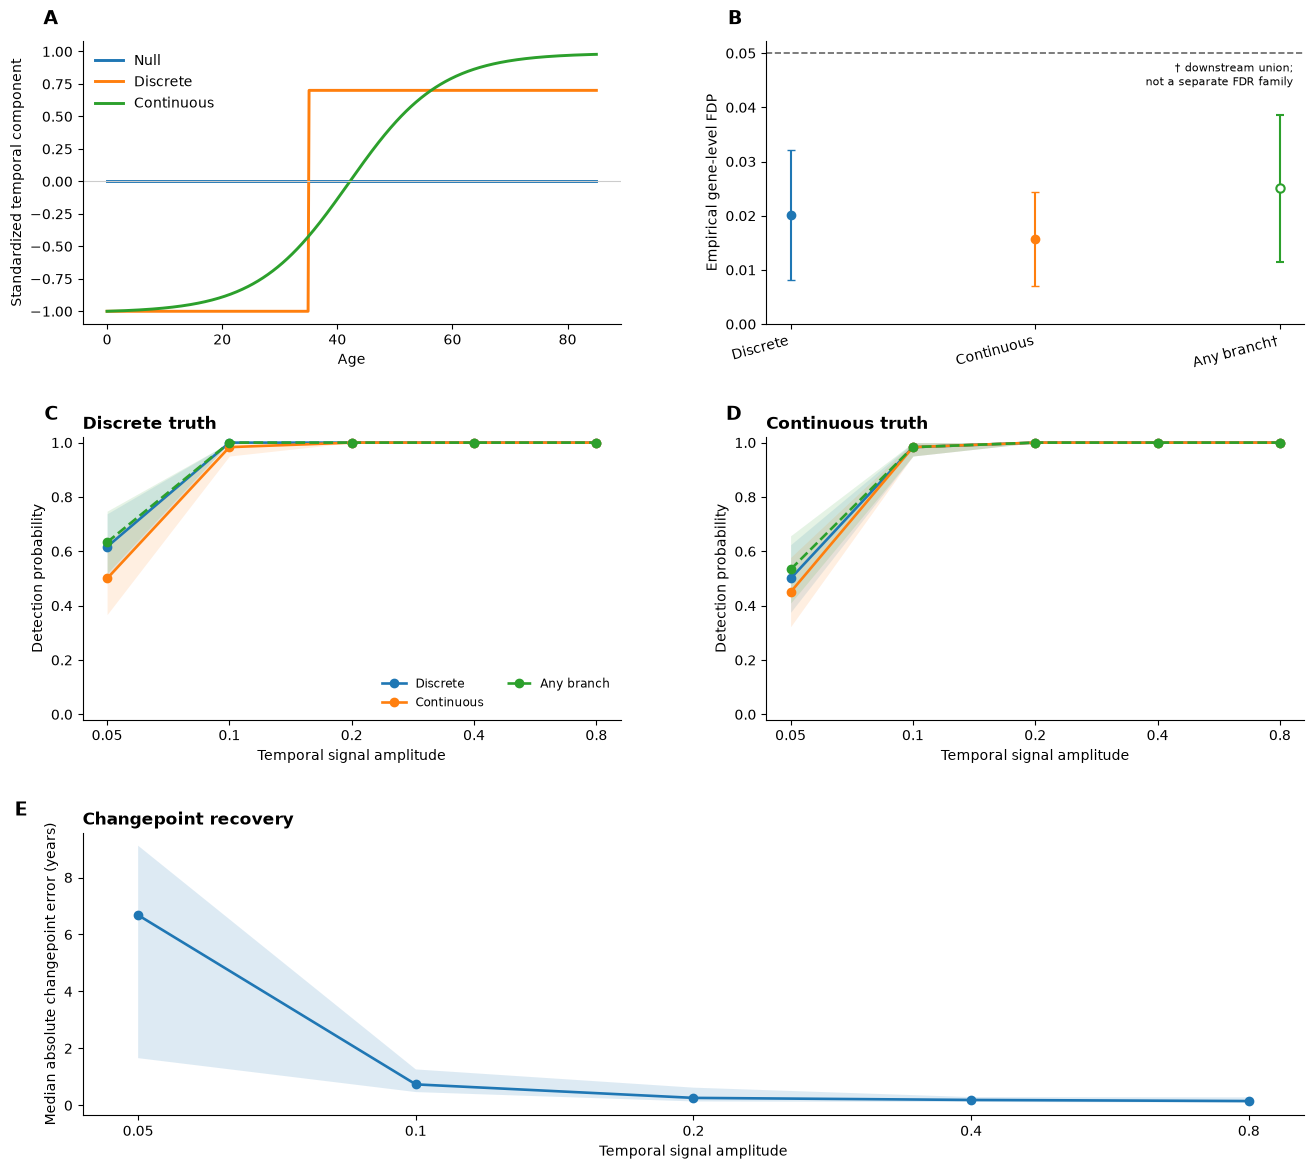

In [12]:
# ============================================================
# 8. Assemble main simulation figure
# ============================================================

fig = plt.figure(
    figsize=(13.5, 12.0)
)

gs = fig.add_gridspec(
    3,
    2,
    left=0.08,
    right=0.985,
    bottom=0.07,
    top=0.965,
    wspace=0.27,
    hspace=0.40,
)


ax_a = fig.add_subplot(
    gs[0, 0]
)

ax_b = fig.add_subplot(
    gs[0, 1]
)

ax_c = fig.add_subplot(
    gs[1, 0]
)

ax_d = fig.add_subplot(
    gs[1, 1]
)

# Changepoint recovery spans the full final row.
ax_e = fig.add_subplot(
    gs[2, :]
)


# ============================================================
# A. Simulation truth
# ============================================================

age_grid = np.linspace(
    0,
    85,
    500,
)


truth_curves = {

    "Null":
        np.zeros_like(
            age_grid
        ),

    "Discrete":
        isim.temporal_basis(
            age_grid,
            "step",
            {
                "change_age":
                    TRUE_CHANGE_AGE,
            },
        ),

    "Continuous":
        isim.temporal_basis(
            age_grid,
            "sigmoid",
            {
                "center":
                    CONTINUOUS_CENTER,

                "scale":
                    CONTINUOUS_SCALE,
            },
        ),
}


for label, curve in (
    truth_curves.items()
):

    ax_a.plot(
        age_grid,
        curve,
        lw=2.1,
        label=label,
    )


ax_a.axhline(
    0,
    lw=0.8,
    color="0.8",
)

ax_a.set_xlabel(
    "Age"
)

ax_a.set_ylabel(
    "Standardized temporal component"
)

ax_a.legend(
    frameon=False,
)


# ============================================================
# B. Empirical gene-level FDP/FDR
# ============================================================

detector_order = [
    "discrete",
    "continuous",
    "union",
]

detector_labels = [
    "Discrete",
    "Continuous",
    "Any branch†",
]


fdr_plot = (
    fdr_summary
    .set_index(
        "detector"
    )
    .loc[
        detector_order
    ]
    .reset_index()
)


x = np.arange(
    len(fdr_plot)
)


for i, row in (
    fdr_plot.iterrows()
):

    yerr = np.array([
        [
            row["mean"]
            - row["ci_low"]
        ],
        [
            row["ci_high"]
            - row["mean"]
        ],
    ])


    if row[
        "detector"
    ] == "union":

        ax_b.errorbar(
            i,
            row["mean"],
            yerr=yerr,
            fmt="o",
            markerfacecolor="white",
            markeredgewidth=1.5,
            capsize=3,
        )

    else:

        ax_b.errorbar(
            i,
            row["mean"],
            yerr=yerr,
            fmt="o",
            capsize=3,
        )


ax_b.axhline(
    ALPHA_FDR,
    ls="--",
    lw=1.2,
    color="0.4",
)

ax_b.set_xticks(
    x
)

ax_b.set_xticklabels(
    detector_labels,
    rotation=15,
    ha="right",
)

ax_b.set_ylabel(
    "Empirical gene-level FDP"
)

ax_b.set_ylim(
    bottom=0
)

ax_b.text(
    0.98,
    0.93,
    (
        "† downstream union;\n"
        "not a separate FDR family"
    ),
    transform=ax_b.transAxes,
    ha="right",
    va="top",
    fontsize=8,
)


# ============================================================
# C-D. Power curves
# ============================================================

POWER_PANELS = [
    (
        ax_c,
        "discrete",
        "Discrete truth",
    ),

    (
        ax_d,
        "continuous",
        "Continuous truth",
    ),
]


power_detector_order = [
    "discrete",
    "continuous",
    "union",
]


power_detector_labels = {

    "discrete":
        "Discrete",

    "continuous":
        "Continuous",

    "union":
        "Any branch",
}


for (
    ax,
    truth_type,
    title,
) in POWER_PANELS:

    sub = (
        power_summary.loc[
            power_summary[
                "truth_type"
            ].eq(
                truth_type
            )
        ]
    )


    for detector in (
        power_detector_order
    ):

        curve = (
            sub.loc[
                sub[
                    "detector"
                ].eq(
                    detector
                )
            ]
            .sort_values(
                "signal_strength"
            )
        )


        linestyle = (
            "--"
            if detector == "union"
            else "-"
        )


        line, = ax.plot(
            curve[
                "signal_strength"
            ],
            curve[
                "mean"
            ],
            marker="o",
            lw=1.9,
            ls=linestyle,
            label=(
                power_detector_labels[
                    detector
                ]
            ),
        )


        ax.fill_between(
            curve[
                "signal_strength"
            ],
            curve[
                "ci_low"
            ],
            curve[
                "ci_high"
            ],
            alpha=0.12,
            color=line.get_color(),
            linewidth=0,
        )


    ax.set_xscale(
        "log",
        base=2,
    )

    ax.set_xticks(
        SIGNAL_STRENGTHS
    )

    ax.set_xticklabels(
        [
            f"{value:g}"
            for value
            in SIGNAL_STRENGTHS
        ]
    )

    ax.set_ylim(
        -0.02,
        1.02,
    )

    ax.set_xlabel(
        "Temporal signal amplitude"
    )

    ax.set_ylabel(
        "Detection probability"
    )

    ax.set_title(
        title,
        loc="left",
        fontweight="bold",
    )


ax_c.legend(
    frameon=False,
    fontsize=8.5,
    ncol=2,
    loc="lower right",
)


# ============================================================
# E. Discrete changepoint localization
# ============================================================

ax_e.plot(
    discrete_location_summary[
        "signal_strength"
    ],
    discrete_location_summary[
        "median_error"
    ],
    marker="o",
    lw=1.9,
)


ax_e.fill_between(
    discrete_location_summary[
        "signal_strength"
    ],
    discrete_location_summary[
        "q25"
    ],
    discrete_location_summary[
        "q75"
    ],
    alpha=0.15,
)


ax_e.set_xscale(
    "log",
    base=2,
)

ax_e.set_xticks(
    SIGNAL_STRENGTHS
)

ax_e.set_xticklabels(
    [
        f"{value:g}"
        for value
        in SIGNAL_STRENGTHS
    ]
)

ax_e.set_xlabel(
    "Temporal signal amplitude"
)

ax_e.set_ylabel(
    "Median absolute changepoint error (years)"
)

ax_e.set_title(
    "Changepoint recovery",
    loc="left",
    fontweight="bold",
)


# ============================================================
# Shared cosmetics
# ============================================================

for ax in (
    ax_a,
    ax_b,
    ax_c,
    ax_d,
    ax_e,
):

    ax.spines[
        "top"
    ].set_visible(
        False
    )

    ax.spines[
        "right"
    ].set_visible(
        False
    )


# ============================================================
# Panel labels
# ============================================================

panel_labels = {
    ax_a: "A",
    ax_b: "B",
    ax_c: "C",
    ax_d: "D",
    ax_e: "E",
}


for ax, label in panel_labels.items():

    ax.text(
        -0.045,
        1.045,
        label,
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=14,
        fontweight="bold",
        clip_on=False,
    )


plt.show()

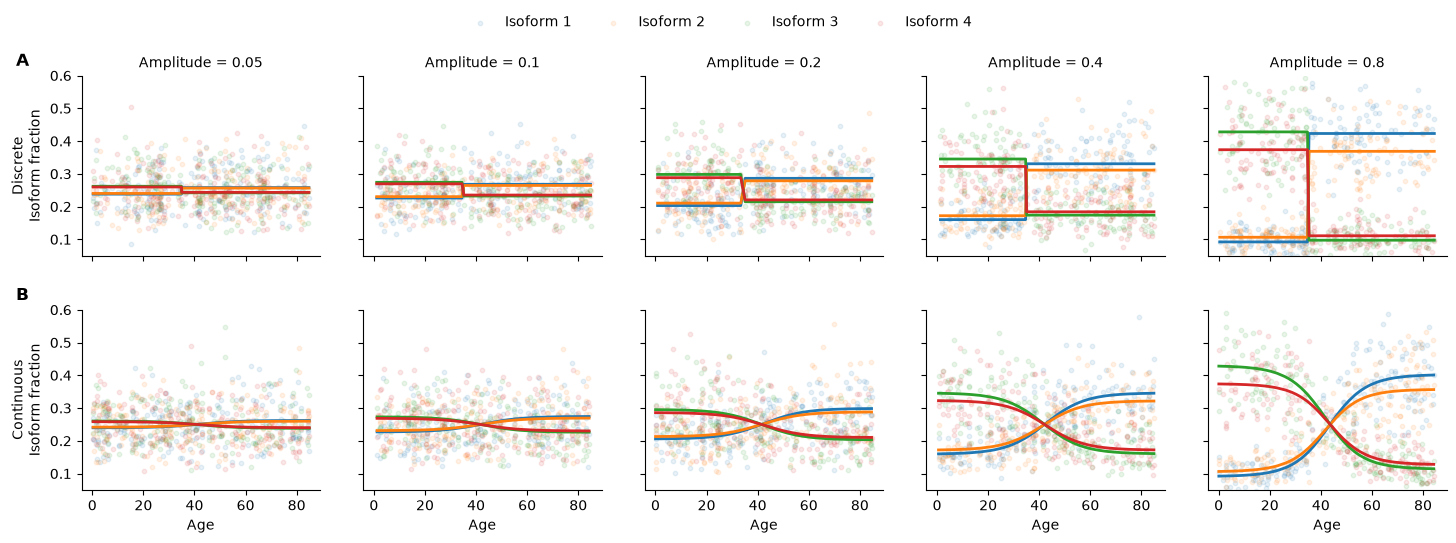

In [13]:
# ============================================================
# Supplementary figure — observed isoform fractions across
# signal amplitudes, with true underlying fraction trajectories
# ============================================================

trajectory_specs = {

    "Discrete": (
        "step",
        {
            "change_age":
                TRUE_CHANGE_AGE,
        },
    ),

    "Continuous": (
        "sigmoid",
        {
            "center":
                CONTINUOUS_CENTER,

            "scale":
                CONTINUOUS_SCALE,
        },
    ),
}


# ------------------------------------------------------------
# Build one representative simulated gene for each condition
# ------------------------------------------------------------

visualization_rows = []


for row, (
    trajectory_name,
    (
        kind,
        params,
    ),
) in enumerate(
    trajectory_specs.items()
):

    for col, amplitude in enumerate(
        SIGNAL_STRENGTHS
    ):

        gene_id = (
            f"VIS_{trajectory_name.upper()}_"
            f"{amplitude:g}"
        )


        scenario = (
            isim.IsoformScenario(
                gene_id=gene_id,
                label=trajectory_name,
                baselines=tuple(
                    np.zeros(K)
                ),
                components=(
                    isim.TemporalComponent(
                        kind=kind,
                        loadings=tuple(
                            REFERENCE_LOADINGS
                        ),
                        amplitude=float(
                            amplitude
                        ),
                        params=params,
                    ),
                ),
                noise_sd=NOISE_SD,
                noise_corr=NOISE_CORR,
            )
        )


        sim = (
            isim.simulate_isovita_dataset(
                (
                    scenario,
                ),
                n_samples=N_SAMPLES,
                age_min=0,
                age_max=85,
                age_design="uniform",
                seed=(
                    BASE_SEED
                    + 10_000
                    + 100 * row
                    + col
                ),
            )
        )


        visualization_rows.append(
            {
                "trajectory_name":
                    trajectory_name,

                "amplitude":
                    float(amplitude),

                "gene_id":
                    gene_id,

                "sim":
                    sim,
            }
        )


# ============================================================
# Assemble 2 × 5 visualization
# ============================================================

fig, axes = plt.subplots(
    len(trajectory_specs),
    len(SIGNAL_STRENGTHS),
    figsize=(15, 5.6),
    sharex=True,
    sharey=True,
    squeeze=False,
)


fig.subplots_adjust(
    left=0.075,
    right=0.985,
    bottom=0.12,
    top=0.86,
    wspace=0.18,
    hspace=0.30,
)


trajectory_names = list(
    trajectory_specs.keys()
)


for item in visualization_rows:

    trajectory_name = (
        item[
            "trajectory_name"
        ]
    )

    amplitude = (
        item[
            "amplitude"
        ]
    )


    row = (
        trajectory_names.index(
            trajectory_name
        )
    )

    col = int(
        np.where(
            np.isclose(
                SIGNAL_STRENGTHS,
                amplitude,
            )
        )[0][0]
    )


    ax = axes[
        row,
        col,
    ]


    gene = (
        item[
            "gene_id"
        ]
    )

    sim = (
        item[
            "sim"
        ]
    )


    frac = (
        sim.fractions
        .loc[
            lambda x:
                x[
                    "gene_id"
                ].eq(
                    gene
                )
        ]
        .copy()
    )


    transcript_order = (
        frac[
            "transcript_id"
        ]
        .drop_duplicates()
        .tolist()
    )


    for isoform_index, tx in enumerate(
        transcript_order
    ):

        sub = (
            frac.loc[
                frac[
                    "transcript_id"
                ].eq(
                    tx
                )
            ]
            .sort_values(
                "age"
            )
        )

        color = (
            f"C{isoform_index}"
        )


        # Observed noisy fractions.
        ax.scatter(
            sub[
                "age"
            ],
            sub[
                "fraction"
            ],
            s=10,
            alpha=0.10,
            color=color,
            label=(
                f"Isoform "
                f"{isoform_index + 1}"
            ),
        )


        # True underlying fraction trajectory.
        ax.plot(
            sub[
                "age"
            ],
            sub[
                "true_fraction"
            ],
            color=color,
            lw=2.0,
        )


    if row == 0:

        ax.set_title(
            f"Amplitude = "
            f"{amplitude:g}",
            fontsize=10,
        )


    if col == 0:

        ax.set_ylabel(
            f"{trajectory_name}\n"
            "Isoform fraction"
        )


    if row == (
        len(
            trajectory_specs
        ) - 1
    ):

        ax.set_xlabel(
            "Age"
        )


    ax.set_ylim(
        0.05,
        0.60,
    )


    ax.spines[
        "top"
    ].set_visible(
        False
    )

    ax.spines[
        "right"
    ].set_visible(
        False
    )


# ============================================================
# Shared legend
# ============================================================

handles, labels = (
    axes[
        0,
        0,
    ]
    .get_legend_handles_labels()
)


fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(
        0.5,
        0.99,
    ),
    ncol=4,
    frameon=False,
)


# ============================================================
# Panel letters
# ============================================================

fig.canvas.draw()


for row, label in enumerate(
    ["A", "B"]
):

    pos = (
        axes[
            row,
            0,
        ]
        .get_position()
    )

    fig.text(
        pos.x0 - 0.035,
        pos.y1 + 0.010,
        label,
        ha="right",
        va="bottom",
        fontsize=12.5,
        fontweight="bold",
    )


plt.show()